# 4.6 Project - Student Performance Prediction
Student ID: lucjus5243

Date: November 1, 2026

Using Data Mining Methods to Make Predictions on Outcomes Using Python

In [2]:
# Step 3: Load the Student Performance Dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_excel("StudentsPerformance.xlsx")

# Display the first five rows
print("First Five Rows:")
display(df.head())

# Display dataset information
print("\nDataset Information:")
df.info()

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Display summary statistics
print("\nSummary Statistics:")
display(df.describe())

First Five Rows:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB

Missing Values:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [3]:
# Step 4: One-Hot Encoding

target = "math score"

X = df.drop(columns=[target])
y = df[target]

X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Encoded Dataset:")
display(X.head())

print("\nTotal Features:", X.shape[1])

print("\nFeature Names:")
print(X.columns.tolist())

Encoded Dataset:


,reading score,writing score,gender_male,race/ethnicity_group B,race/ethnicity_group C,race/ethnicity_group D,race/ethnicity_group E,parental level of education_bachelor's degree,parental level of education_high school,parental level of education_master's degree,parental level of education_some college,parental level of education_some high school,lunch_standard,test preparation course_none
0,72,74,0,1,0,0,0,1,0,0,0,0,1,1
1,90,88,0,0,1,0,0,0,0,0,1,0,1,0
2,95,93,0,1,0,0,0,0,0,1,0,0,1,1
3,57,44,1,0,0,0,0,0,0,0,0,0,0,1
4,78,75,1,0,1,0,0,0,0,0,1,0,1,1



Total Features: 14

Feature Names:
['reading score', 'writing score', 'gender_male', 'race/ethnicity_group B', 'race/ethnicity_group C', 'race/ethnicity_group D', 'race/ethnicity_group E', "parental level of education_bachelor's degree", 'parental level of education_high school', "parental level of education_master's degree", 'parental level of education_some college', 'parental level of education_some high school', 'lunch_standard', 'test preparation course_none']


In [5]:
# Step 5: Train and Test Linear Regression

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

# Train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Linear Regression model trained successfully!")

Training Samples: 800
Testing Samples: 200
Linear Regression model trained successfully!


In [4]:
# Step 6: Model Evaluation

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predict math scores
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Display results
print("Model Evaluation Results")
print("------------------------")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R-Squared Value: {r2:.4f}")

Model Evaluation Results
------------------------
Mean Absolute Error (MAE): 4.2148
Mean Squared Error (MSE): 29.0952
R-Squared Value: 0.8804


Feature Importance Ranking:


,Feature,Coefficient,Absolute_Importance
2,gender_male,13.064884,13.064884
6,race/ethnicity_group E,4.892649,4.892649
12,lunch_standard,3.510075,3.510075
13,test preparation course_none,3.289642,3.289642
9,parental level of education_master's degree,-1.400489,1.400489
10,parental level of education_some college,0.998856,0.998856
8,parental level of education_high school,0.929312,0.929312
11,parental level of education_some high school,0.756470,0.756470
1,writing score,0.724148,0.724148
7,parental level of education_bachelor's degree,-0.716901,0.716901


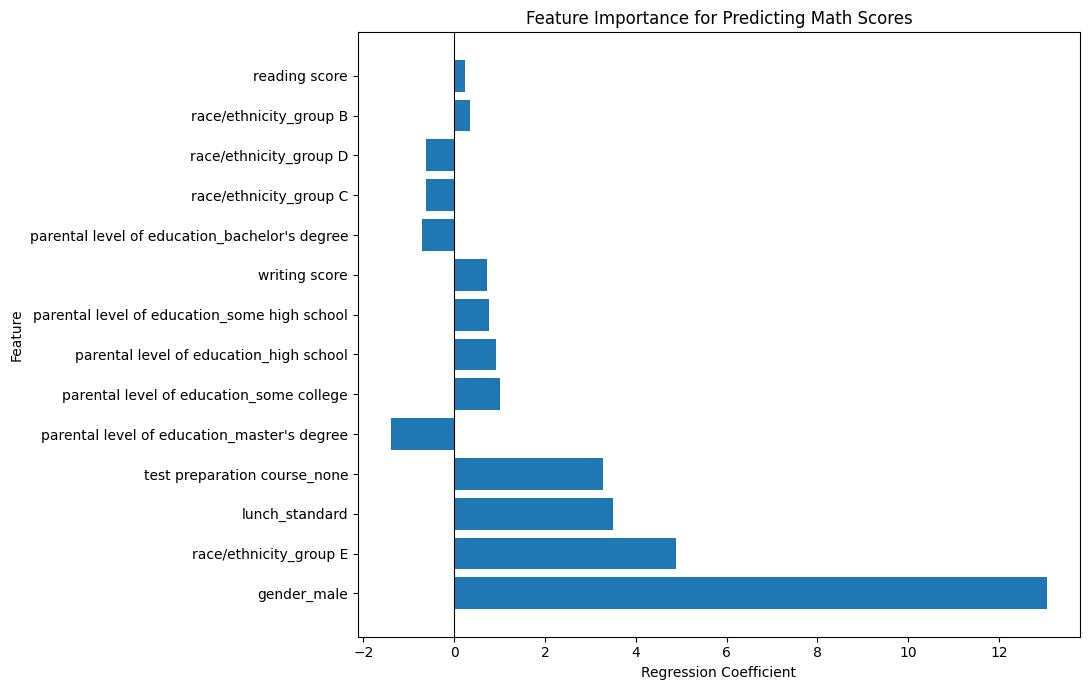

In [5]:
# Step 7: Feature Importance

import pandas as pd
import matplotlib.pyplot as plt

# Calculate feature importance
importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

# Calculate absolute importance
importance["Absolute_Importance"] = (
    importance["Coefficient"].abs()
)

# Rank features by importance
importance = importance.sort_values(
    by="Absolute_Importance",
    ascending=False
)

# Display the ranking
print("Feature Importance Ranking:")
display(importance)

# Create a graph
plt.figure(figsize=(11, 7))

plt.barh(
    importance["Feature"],
    importance["Coefficient"]
)

plt.xlabel("Regression Coefficient")
plt.ylabel("Feature")
plt.title("Feature Importance for Predicting Math Scores")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

# 5.5 Project – Prescriptive Analytics and Final Project Submission

Student: Lucas Justiniano  
Student ID: lucjus5243  
Date: November 5, 2026

## Actionable Features

In the Student Performance dataset, reading scores and lunch status are two features that may be influenced through school programs.

Reading scores can potentially improve through tutoring, literacy programs, and additional academic support. Lunch status reflects access to meal assistance and socioeconomic circumstances. Schools can provide nutritional support and other resources to help students experiencing financial challenges.

These interventions may improve student outcomes, but the relationships identified by the machine learning model do not necessarily establish cause and effect.


In [6]:

# 5.5 Project - Student Performance Intervention Analysis

import pandas as pd
import numpy as np

# Use the trained model from Project 4.6
# Make sure the previous model-training cell has been run

# Select students with math scores below the median
median_math = df["math score"].median()
low_students = df[df["math score"] < median_math].copy()

# Use the same features as the trained model
X_before = X.loc[low_students.index].copy()
X_after = X_before.copy()

# Intervention 1: Increase reading scores by 5%
X_after["reading score"] = np.minimum(
    X_after["reading score"] * 1.05, 100
)

# Intervention 2: Simulate a 5% reduction
# in the number receiving free/reduced lunch
lunch_column = "lunch_standard"

if lunch_column in X_after.columns:
    reduced_lunch_students = X_after.index[
        X_after[lunch_column] == 0
    ]

    number_to_change = round(
        len(reduced_lunch_students) * 0.05
    )

    students_to_change = reduced_lunch_students[:number_to_change]

    X_after.loc[students_to_change, lunch_column] = 1

# Predict math scores before and after intervention
predicted_before = model.predict(X_before)
predicted_after = model.predict(X_after)

# Create results table
results = pd.DataFrame({
    "Predicted Math Before": predicted_before,
    "Predicted Math After": predicted_after
}, index=low_students.index)

results["Improvement"] = (
    results["Predicted Math After"]
    - results["Predicted Math Before"]
)

# Display results
print("5.5 Project - Intervention Results")
print("--------------------------------")
print("Students analyzed:", len(results))
print("Median math score:", median_math)
print("Average predicted math score before:",
      round(results["Predicted Math Before"].mean(), 2))
print("Average predicted math score after:",
      round(results["Predicted Math After"].mean(), 2))
print("Average predicted improvement:",
      round(results["Improvement"].mean(), 2))

display(results.head(10))


5.5 Project - Intervention Results
--------------------------------
Students analyzed: 483
Median math score: 66.0
Average predicted math score before: 55.22
Average predicted math score after: 56.01
Average predicted improvement: 0.79


,Predicted Math Before,Predicted Math After,Improvement
3,50.757824,54.940563,4.182739
7,45.190948,49.208471,4.017523
8,66.091818,70.357165,4.265347
9,44.034531,48.252673,4.218143
10,58.727398,59.364659,0.637261
11,51.750402,52.364061,0.613659
12,69.156482,70.112373,0.955891
14,48.996507,49.621967,0.625460
17,21.321802,25.209513,3.887711
18,43.350033,47.355756,4.005722


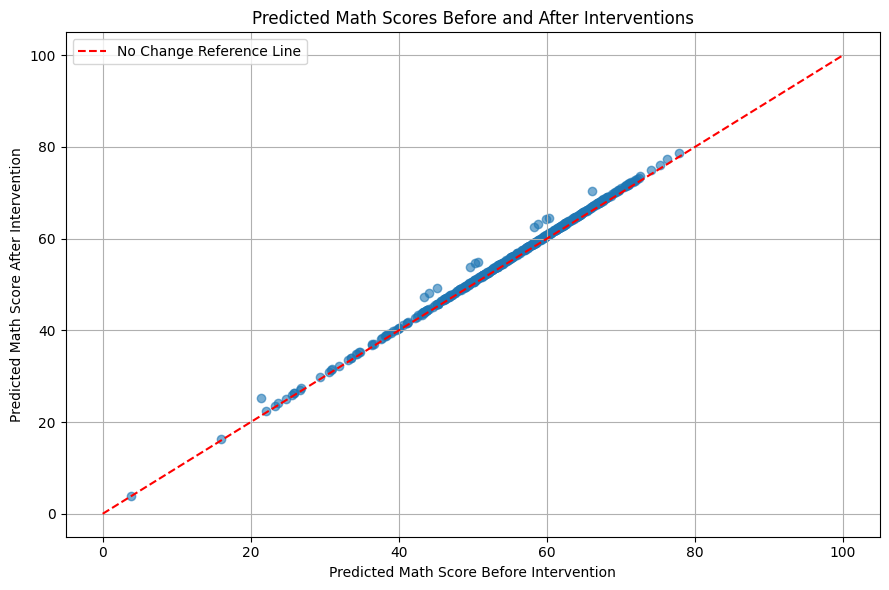

In [7]:

# 5.5 Project - Scatter Plot of Intervention Results

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    results["Predicted Math Before"],
    results["Predicted Math After"],
    alpha=0.6
)

plt.plot([0, 100], [0, 100], "r--",
         label="No Change Reference Line")

plt.xlabel("Predicted Math Score Before Intervention")
plt.ylabel("Predicted Math Score After Intervention")
plt.title("Predicted Math Scores Before and After Interventions")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
